# 2D Gaussian toy model

The same tests as in `Toy_gaussian.ipynb`, with the Gaussian in two dimensions instead of one. The helper functions are in `Toy_nd_utils.py` and work for any number of dimensions $n$. Only the plots here are made for $n = 2$.

The structure follows the 1D notebook:
1. The Gaussian and its Lipschitz constant.
2. The floor, the best possible $L$-Lipschitz fit: what it looks like, its MSE and width as a function of $L$, and the integrated errors over $(\sigma, L)$.
3. Trained networks against the floor.
4. Sine-wave noise, which becomes plane waves $A \sin(k \cdot x)$ in 2D.
5. White noise.

**Which norm?** In 1D a slope can only be measured one way. In $n$ dimensions the Lipschitz condition $|f(x) - f(x')| \le L\,\|x - x'\|$ depends on the norm. The `LipschitzModel` networks (first layer normalised with `one-inf`, i.e. $\max |W_{ij}| \le 1$, the others with `inf`, i.e. row sums $\le 1$) are Lipschitz in the $L^1$ norm of the input. This is the same as bounding every partial derivative on its own, $\|\nabla f\|_\infty = \max_i |\partial_i f| \le L$. Along a diagonal a network can therefore be steeper than $L$, up to $\sqrt{n}\,L$. All Lipschitz constants, floors and measured slopes below use this norm, so that they are the right reference for the networks.

**Runtime.** The floor sections take a few minutes. Every network section trains its networks in parallel, one process per network, and takes roughly half an hour to an hour on 16 cores. Set `QUICK = True` below for a fast test run with small grids, short training and fewer seeds. The numbers from a quick run are not meaningful.

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

In [2]:
# "Homemade" modules
%load_ext autoreload
%autoreload 2
from Toy_utils import gaussian_lipschitz_constant, noise_removed, REPORT_STYLE
from Toy_nd_utils import (gaussian_nd, isotropic_cov, gaussian_lipschitz_constant_nd, isotropic_lipschitz_constant,
                          pyramid_radius, make_grid, grid_spacing, grid_integral, grid_gradient, grid_lipschitz_estimate,
                          central_line, profile, lipschitz_floor_nd, fwhm_equivalent, fwhm_along, train_many,
                          wavevector, plane_wave_noise, plane_wave_slope, fourier_modes, mode_amplitude_nd,
                          radial_spectrum, band_power)

QUICK = False   # True: small grids, short training and fewer seeds, only to check that everything runs
DIM = 2         # number of input dimensions. The utilities work for any DIM, the plots below are made for DIM = 2

PLOT_DIR = "Plots/Toy_2d"
os.makedirs(PLOT_DIR, exist_ok=True)

PANEL_SIZE = (3.1, 2.8)  # inches, close to the final size of a 0.48\textwidth subfigure (two side by side)
C_TRUE, C_FLOOR, C_NET, C_MUTED, C_REF = "#1f1f1f", "#2a78d6", "#eb6834", "#6b6a66", "#9a9893"

# Directions used for the cuts through the peak: along the first axis and along the diagonal
AXIS_DIRECTION = np.eye(DIM)[0]
DIAGONAL_DIRECTION = np.ones(DIM)

# The Gaussian function
The normalised Gaussian in $n$ dimensions is
$$
f(x) = \frac{1}{\sqrt{(2\pi)^n \det\Sigma}}\exp\left(-\tfrac{1}{2} (x - \mu)^T \Sigma^{-1} (x - \mu)\right),
$$
and we use the isotropic case $\Sigma = \sigma^2 I$, $\mu = 0$. Its Lipschitz constant in the networks' norm, the largest partial derivative, is
$$
L_\mathrm{true} = e^{-1/2} f_\mathrm{max} \max_i \sqrt{(\Sigma^{-1})_{ii}} \;\overset{\text{isotropic}}{=}\; \frac{e^{-1/2}}{(2\pi)^{n/2}\,\sigma^{n+1}},
$$
which is $(\sigma^2\sqrt{2\pi e})^{-1}$ in 1D. For an isotropic Gaussian the $L^1$ and the Euclidean Lipschitz constant are the same, since the gradient points along the line to the centre, and the largest slope along an axis is the largest slope overall. In $n$ dimensions $L_\mathrm{true}$ grows as $\sigma^{-(n+1)}$: the peak gets higher ($\sigma^{-n}$) as well as narrower.

sigma = 0.2: L_true from the formula = 12.0665, largest |df/dx_i| on the grid = 12.0659


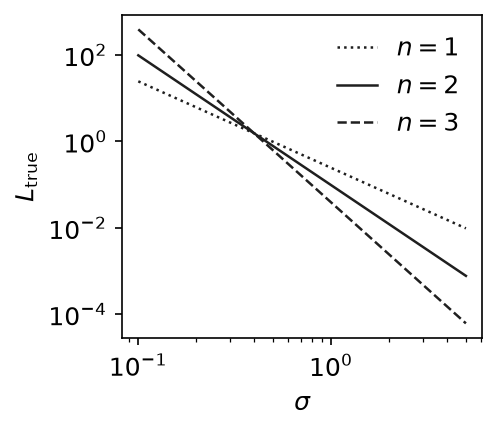

In [3]:
# The Lipschitz constant as a function of the standard deviation, for 1, 2 and 3 dimensions
sigma_values = np.logspace(-1, 0.7, 40)
assert np.allclose(isotropic_lipschitz_constant(sigma_values, 1), gaussian_lipschitz_constant(sigma_values))  # same as 1D

# Numerical check of the formula: the largest partial derivative of the Gaussian on a fine grid
SIGMA_CHECK = 0.2
axes_check, X_check = make_grid(5 * SIGMA_CHECK, 801, DIM)
f_check = gaussian_nd(X_check, np.zeros(DIM), isotropic_cov(SIGMA_CHECK, DIM))
print(f"sigma = {SIGMA_CHECK}: L_true from the formula = {isotropic_lipschitz_constant(SIGMA_CHECK, DIM):.4f}, "
      f"largest |df/dx_i| on the grid = {np.abs(grid_gradient(f_check, axes_check)).max():.4f}")

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    for n, ls in zip([1, 2, 3], [":", "-", "--"]):
        ax.plot(sigma_values, isotropic_lipschitz_constant(sigma_values, n), color=C_TRUE, ls=ls, lw=1.2, label=f"$n = {n}$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\sigma$")
    ax.set_ylabel(r"$L_\mathrm{true}$")
    ax.legend()
    fig.savefig(f"{PLOT_DIR}/gaussian_lipschitz_constant.pdf")
    plt.show()

# Floor function
The floor is the best possible $L$-Lipschitz fit, the lowest MSE an $L$-Lipschitz network can reach:
$$
\min_g \sum_{x} \big(g(x) - f(x)\big)^2 \quad\text{subject to}\quad |g(x) - g(x')| \le L\,\|x - x'\|_1 \;\text{for all grid points } x, x'.
$$
On a regular grid the $L^1$ distance between two points is the length of the shortest path along the grid lines, so it is enough to constrain neighbouring points along each axis. This is exact, not an approximation, and keeps the problem sparse: `lipschitz_floor_nd` solves it with an interior point method in a few seconds for a $300 \times 300$ grid. In 1D it gives the same floor as before. The 1D notebook's peaks and ISEs for $L = 1, 3, 10, 20$ are reproduced exactly.

**What to expect.** Because every partial derivative is bounded on its own, the steepest peak an $L$-Lipschitz function can have is the pyramid $h - L\|x\|_1$. Its contours are diamonds, not circles. Where the slope budget runs out, the 2D floor is therefore expected to be wider along the axes than along the diagonals: the 2D version of the 1D tent.

## Fitting the floor function

In [4]:
# The Gaussian on a grid, and the floors for selected L
SIGMA = 0.1
MU = np.zeros(DIM)
COV = isotropic_cov(SIGMA, DIM)
L_true = isotropic_lipschitz_constant(SIGMA, DIM)

L_RATIOS_SHOW = [0.04, 0.12, 0.4, 0.8]           # L / L_true, about the L = 1, 3, 10, 20 of the 1D notebook
L_show = [r * L_true for r in L_RATIOS_SHOW]      # all below L_true: for L >= L_true the floor is the truth itself

# The grid has to be wide enough for the floor with the smallest L to come down to zero inside it
POINTS_PER_SIGMA = 4 if QUICK else 15
HALF_WIDTH = max(6 * SIGMA, 1.2 * pyramid_radius(min(L_show), DIM))
N_POINTS = 2 * int(HALF_WIDTH / SIGMA * POINTS_PER_SIGMA) + 1   # odd, so the peak sits on a grid point
axes, X = make_grid(HALF_WIDTH, N_POINTS, DIM)
y_grid = gaussian_nd(X, MU, COV)
print(f"L_true = {L_true:.2f}, grid: {N_POINTS}^{DIM} points on [-{HALF_WIDTH:.2f}, {HALF_WIDTH:.2f}]^{DIM}")

floors = {}
for L in L_show:
    floors[L], mse, info = lipschitz_floor_nd(y_grid, axes, L, return_info=True)
    print(f"L = {L:6.2f} (L / L_true = {L / L_true:.2f}): MSE = {mse:.3e}, {info['iterations']} iterations, "
          f"converged: {info['converged']}, peak = {floors[L].max():.3f} (true {y_grid.max():.3f})")

L_true = 96.53, grid: 263^2 points on [-0.88, 0.88]^2
L =   3.86 (L / L_true = 0.04): MSE = 1.606e+00, 11 iterations, converged: True, peak = 2.817 (true 15.915)
L =  11.58 (L / L_true = 0.12): MSE = 9.266e-01, 10 iterations, converged: True, peak = 5.859 (true 15.915)
L =  38.61 (L / L_true = 0.40): MSE = 1.669e-01, 12 iterations, converged: True, peak = 12.384 (true 15.915)
L =  77.23 (L / L_true = 0.80): MSE = 2.169e-03, 11 iterations, converged: True, peak = 15.915 (true 15.915)


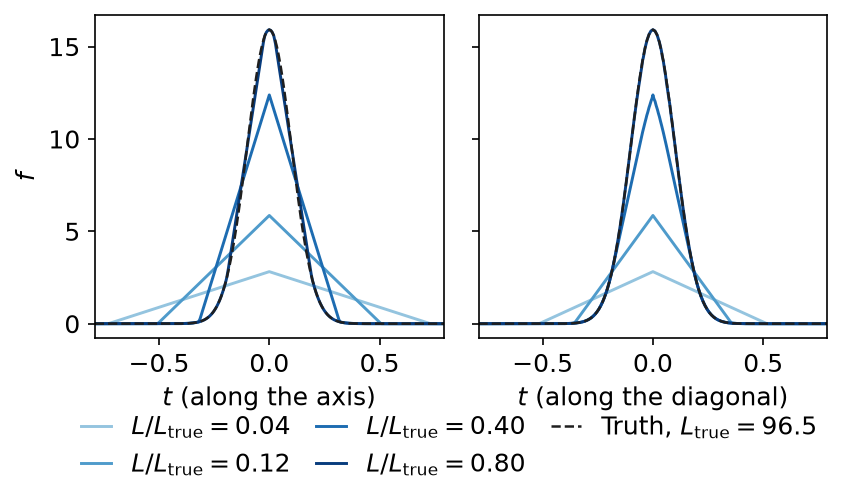

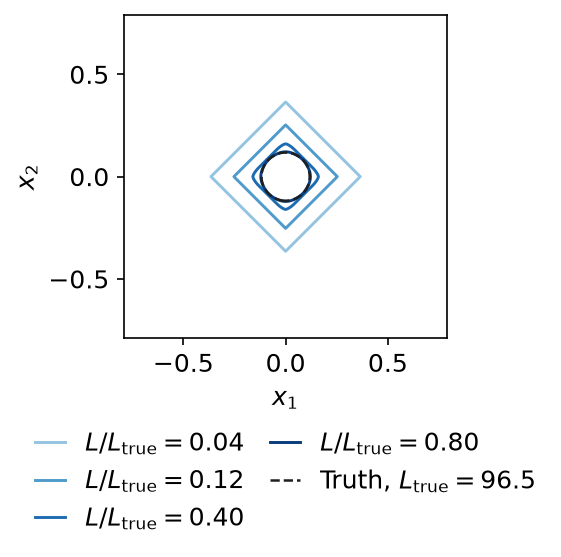

In [5]:
# Cuts through the peak along an axis and along the diagonal (t = distance from the peak), and the half-maximum contours

t_cut = np.linspace(-HALF_WIDTH, HALF_WIDTH, 1201)
truth_axis = profile(axes, y_grid, AXIS_DIRECTION, t_cut)
truth_diagonal = profile(axes, y_grid, DIAGONAL_DIRECTION, t_cut)
floor_axis = {L: profile(axes, floors[L], AXIS_DIRECTION, t_cut) for L in L_show}
floor_diagonal = {L: profile(axes, floors[L], DIAGONAL_DIRECTION, t_cut) for L in L_show}

# Zoom to where the floors differ visibly from the truth (but stay inside the grid)
peak_true = y_grid.max()
differs = np.any([np.abs(g - truth_axis) > 0.01 * peak_true for g in floor_axis.values()], axis=0)
t_zoom = min(HALF_WIDTH, 1.15 * np.abs(t_cut[differs]).max()) if differs.any() else 4 * SIGMA

shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L

with plt.rc_context(REPORT_STYLE):
    # (a) Cuts along the axis and along the diagonal, on the same distance axis
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), sharey=True, gridspec_kw=dict(wspace=0.1))
    for ax, truth, cut, name in [(axs[0], truth_axis, floor_axis, "axis"), (axs[1], truth_diagonal, floor_diagonal, "diagonal")]:
        floor_lines = []
        for L, c in zip(L_show, shades):
            line, = ax.plot(t_cut, cut[L], color=c, lw=1.4, label=rf"$L/L_\mathrm{{true}} = {L / L_true:.2f}$")
            floor_lines.append(line)
        truth_line, = ax.plot(t_cut, truth, color=C_TRUE, lw=1.2, ls="--", label=rf"Truth, $L_\mathrm{{true}} = {L_true:.1f}$")
        ax.set_xlim(-t_zoom, t_zoom)
        ax.set_xlabel(rf"$t$ (along the {name})")
    axs[0].set_ylabel(r"$f$")
    fig.legend(handles=floor_lines + [truth_line], loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3,
               handlelength=1.2, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_floor_fits_cuts.pdf")
    plt.show()

    # (b) Half-maximum contours: circles for the Gaussian, diamonds where the floor runs out of slope budget
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    for L, c in zip(L_show, shades):
        ax.contour(axes[0], axes[1], floors[L].T, levels=[floors[L].max() / 2], colors=[c], linewidths=1.4)
    ax.contour(axes[0], axes[1], y_grid.T, levels=[peak_true / 2], colors=[C_TRUE], linewidths=1.2, linestyles="--")
    ax.set_xlim(-t_zoom, t_zoom)
    ax.set_ylim(-t_zoom, t_zoom)
    ax.set_aspect("equal")
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
    ax.legend(handles=floor_lines + [truth_line], loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2,
              handlelength=1.2, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_floor_half_max_contours.pdf")
    plt.show()

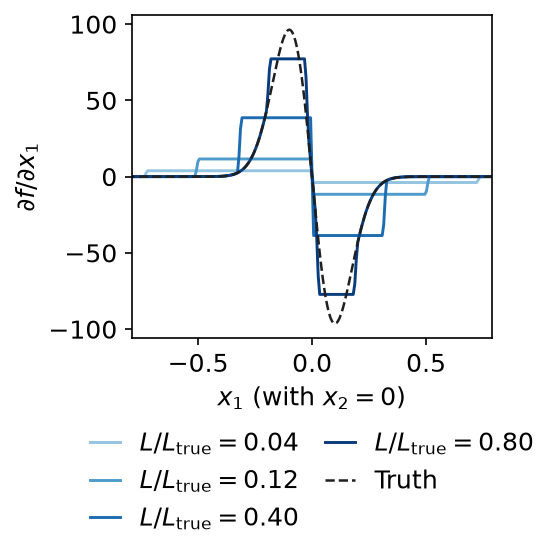

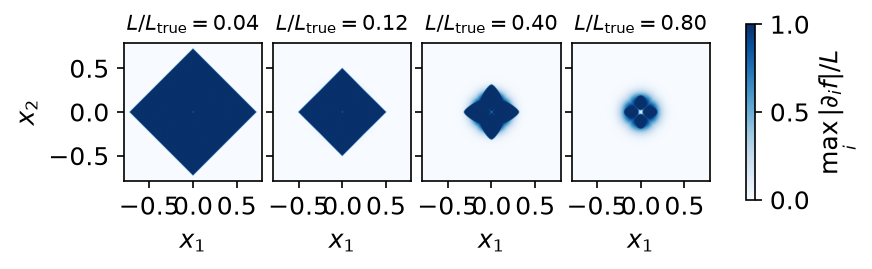

In [6]:
# Slopes of the floor fits (theory). Left: the partial derivative df/dx_1 along the x_1 axis, the 2D version of the
# 1D slope plot. Right: where the slope budget is used up, max_i |df/dx_i| / L for every L.
slope_true_axis = central_line(grid_gradient(y_grid, axes)[..., 0])
floor_gradients = {L: grid_gradient(floors[L], axes) for L in L_show}

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    slope_lines = []
    for L, c in zip(L_show, shades):
        line, = ax.plot(axes[0], central_line(floor_gradients[L][..., 0]), color=c, lw=1.4,
                        label=rf"$L/L_\mathrm{{true}} = {L / L_true:.2f}$")
        slope_lines.append(line)
    truth_slope_line, = ax.plot(axes[0], slope_true_axis, color=C_TRUE, lw=1.2, ls="--", label="Truth")
    ax.set_xlim(-t_zoom, t_zoom)
    ax.set_xlabel(r"$x_1$ (with $x_2 = 0$)"); ax.set_ylabel(r"$\partial f/\partial x_1$")
    ax.legend(handles=slope_lines + [truth_slope_line], loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2,
              handlelength=1.2, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_floor_slopes.pdf")
    plt.show()

    # Share of the slope budget that is used. Central differences round off the kinks, so the maps can dip below 1 there.
    fig, axs = plt.subplots(1, len(L_show), figsize=(6.3, 1.9), sharey=True, gridspec_kw=dict(wspace=0.08))
    for ax, L in zip(axs, L_show):
        budget = np.abs(floor_gradients[L]).max(axis=-1) / L
        image = ax.imshow(budget.T, origin="lower", extent=[axes[0][0], axes[0][-1], axes[1][0], axes[1][-1]],
                          vmin=0, vmax=1, cmap="Blues")
        ax.set_xlim(-t_zoom, t_zoom); ax.set_ylim(-t_zoom, t_zoom)
        ax.set_title(rf"$L/L_\mathrm{{true}} = {L / L_true:.2f}$", fontsize=10)
        ax.set_xlabel(r"$x_1$")
    axs[0].set_ylabel(r"$x_2$")
    fig.colorbar(image, ax=axs, shrink=0.8, label=r"$\max_i |\partial_i f| / L$")
    fig.savefig(f"{PLOT_DIR}/gaussian_floor_slope_budget.pdf")
    plt.show()

In 1D the floor is a tent: it leaves the Gaussian where the Gaussian gets too steep, rises at exactly $\pm L$ up to the peak, and starts rising earlier, which makes it wider and lower. In 2D the same happens along every direction, but with the budget measured per axis. The slope maps show where the floor runs at its full budget. Comparing the half-maximum contours and the two cuts shows how far the floor is pulled from circles towards diamonds.

## MSE and FWHM of the floor function
The same scans as in 1D. The MSE is the mean over a fixed grid. The width is measured in three ways: the equivalent FWHM (the diameter of the disc with the same area as the region above half maximum, which is the usual FWHM for a round peak), and the FWHM along an axis and along the diagonal. If the floor turns into a diamond, the axis width grows faster than the diagonal width.

In [7]:
# One fixed grid for the whole scan, wide enough for the smallest L
N_SCAN = 6 if QUICK else 40
POINTS_PER_SIGMA_SCAN = 3 if QUICK else 8
L_scan = np.logspace(np.log10(0.01 * L_true), np.log10(2 * L_true), N_SCAN)
L_scan_zoom = np.logspace(np.log10(0.4 * L_true), np.log10(1.01 * L_true), N_SCAN)

HALF_WIDTH_SCAN = max(6 * SIGMA, 1.2 * pyramid_radius(min(L_scan), DIM))
axes_scan, X_scan = make_grid(HALF_WIDTH_SCAN, 2 * int(HALF_WIDTH_SCAN / SIGMA * POINTS_PER_SIGMA_SCAN) + 1, DIM)
y_scan = gaussian_nd(X_scan, MU, COV)
print(f"Scan grid: {len(axes_scan[0])}^{DIM} points on [-{HALF_WIDTH_SCAN:.2f}, {HALF_WIDTH_SCAN:.2f}]^{DIM}")


def widths(f, axes):
    """The three widths used in the scans: equivalent FWHM, FWHM along an axis and along the diagonal."""
    return {"equivalent": fwhm_equivalent(f, axes),
            "axis": fwhm_along(axes, f, AXIS_DIRECTION),
            "diagonal": fwhm_along(axes, f, DIAGONAL_DIRECTION)}


def floor_scan(L_values, y, axes):
    """MSE and the three widths of the floor, for every L. Returns a dictionary of arrays."""
    results = {"MSE": [], "equivalent": [], "axis": [], "diagonal": []}
    for L in L_values:
        floor, mse = lipschitz_floor_nd(y, axes, L)
        results["MSE"].append(mse)
        for name, value in widths(floor, axes).items():
            results[name].append(value)
    return {name: np.array(values) for name, values in results.items()}


widths_true = widths(y_scan, axes_scan)
scan = floor_scan(L_scan, y_scan, axes_scan)
print("Wide scan done")
scan_zoom = floor_scan(L_scan_zoom, y_scan, axes_scan)
print("Zoomed scan done")

Scan grid: 223^2 points on [-1.39, 1.39]^2
Wide scan done
Zoomed scan done


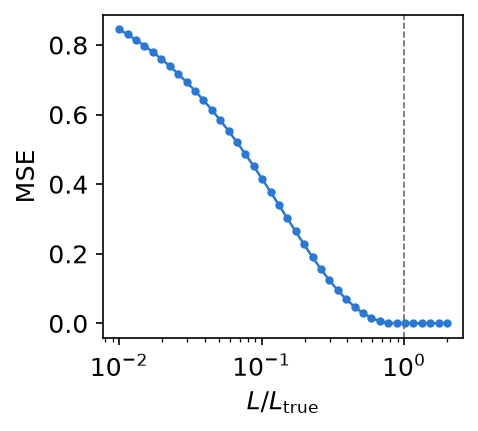

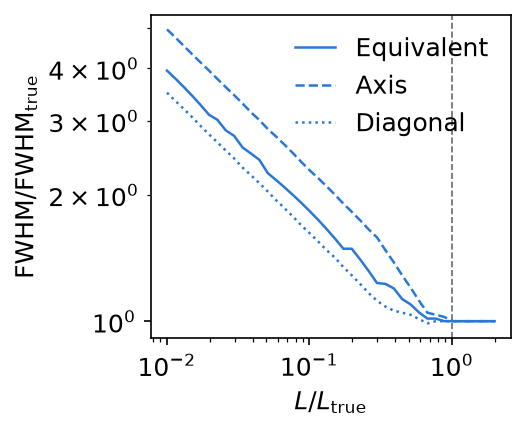

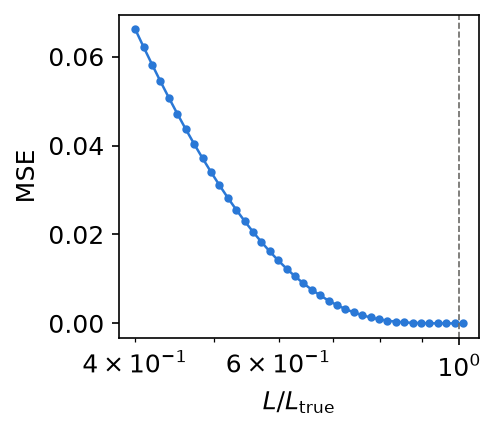

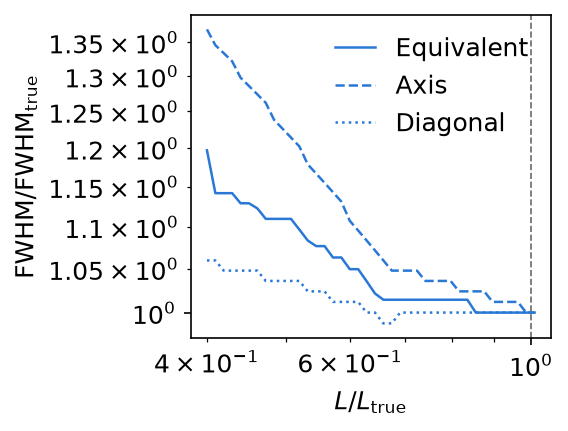

In [8]:
# MSE and widths of the best Lipschitz fit as a function of L, for the wide and the zoomed scan
def plot_floor_scan(L_values, results, suffix):
    with plt.rc_context(REPORT_STYLE):
        fig, ax = plt.subplots(figsize=PANEL_SIZE)
        ax.plot(L_values / L_true, results["MSE"], "-o", color=C_FLOOR, markersize=3, lw=1.2)
        ax.axvline(1, color=C_MUTED, lw=0.8, ls="--")
        ax.set_xscale("log")
        ax.set_xlabel(r"$L / L_\mathrm{true}$"); ax.set_ylabel("MSE")
        fig.savefig(f"{PLOT_DIR}/gaussian_MSE_floors{suffix}.pdf")
        plt.show()

        fig, ax = plt.subplots(figsize=PANEL_SIZE)
        for name, ls in [("equivalent", "-"), ("axis", "--"), ("diagonal", ":")]:
            ax.plot(L_values / L_true, results[name] / widths_true[name], ls, color=C_FLOOR, lw=1.2, label=name.capitalize())
        ax.axvline(1, color=C_MUTED, lw=0.8, ls="--")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$L / L_\mathrm{true}$"); ax.set_ylabel(r"$\mathrm{FWHM}/\mathrm{FWHM}_\mathrm{true}$")
        ax.legend()
        fig.savefig(f"{PLOT_DIR}/gaussian_FWHM_floors{suffix}.pdf")
        plt.show()


plot_floor_scan(L_scan, scan, "")
plot_floor_scan(L_scan_zoom, scan_zoom, "_zoom")

## Integrated floor errors compared
The same sanity check as in 1D. Rescaling $x \to x/\sigma$ maps a Gaussian of width $\sigma$ onto one of width 1, with $f_\sigma(x) = \sigma^{-n} f_1(x/\sigma)$ and $L_\mathrm{true} \propto \sigma^{-(n+1)}$. At a fixed $L/L_\mathrm{true}$ the floors are therefore rescaled copies of each other, and
$$
\int |g - f|\,\mathrm{d}^n x \ \text{ is the same for every } \sigma, \qquad \int (g - f)^2\,\mathrm{d}^n x \propto \sigma^{-n}.
$$
In 1D the squared error spreads out as $1/\sigma$, in 2D it should spread out as $1/\sigma^2$.

In [9]:
sigma_values = np.logspace(-1, 0.5, 2 if QUICK else 5)
r_values = np.logspace(-2, np.log10(2), 4 if QUICK else 20)   # L / L_true, the same grid for every sigma
POINTS_PER_SIGMA_IE = 3 if QUICK else 8                       # the same resolution for every sigma

ISE_matrix = np.zeros((len(sigma_values), len(r_values)))
IAE_matrix = np.zeros_like(ISE_matrix)

for i, sigma in enumerate(sigma_values):
    L_true_sigma = isotropic_lipschitz_constant(sigma, DIM)   # own name, so the global L_true is not overwritten
    for j, r in enumerate(r_values):
        L = r * L_true_sigma

        # Scale the grid with sigma, so it contains the same features for every combination of sigma and L
        half_width = max(6 * sigma, 1.2 * pyramid_radius(L, DIM))
        axes_ie, X_ie = make_grid(half_width, 2 * int(half_width / sigma * POINTS_PER_SIGMA_IE) + 1, DIM)
        y_ie = gaussian_nd(X_ie, np.zeros(DIM), isotropic_cov(sigma, DIM))
        floor, _ = lipschitz_floor_nd(y_ie, axes_ie, L)

        ISE_matrix[i, j] = grid_integral((y_ie - floor) ** 2, axes_ie)
        IAE_matrix[i, j] = grid_integral(np.abs(y_ie - floor), axes_ie)
    print(f"sigma = {sigma:.2f} done")

# Check of the scaling: IAE and sigma^n * ISE should not depend on sigma
below = r_values < 1
print(f"Largest relative spread over sigma: IAE {np.max(np.ptp(IAE_matrix[:, below], axis=0) / IAE_matrix[:, below].mean(axis=0)):.1e}, "
      f"sigma^{DIM} ISE {np.max(np.ptp((sigma_values[:, None] ** DIM * ISE_matrix)[:, below], axis=0) / (sigma_values[:, None] ** DIM * ISE_matrix)[:, below].mean(axis=0)):.1e}")

sigma = 0.10 done
sigma = 0.24 done
sigma = 0.56 done
sigma = 1.33 done
sigma = 3.16 done
Largest relative spread over sigma: IAE 6.8e-03, sigma^2 ISE 1.0e-03


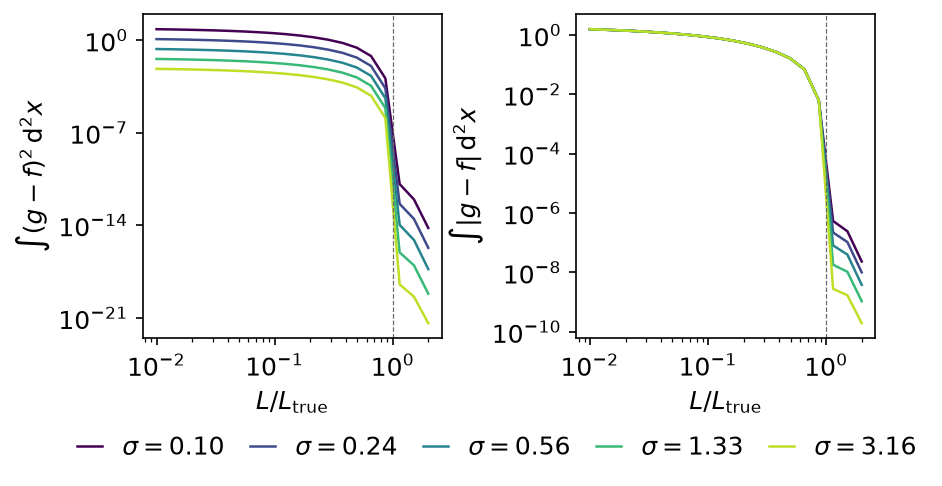

In [10]:
# The squared and the absolute error side by side, with one shared legend underneath
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sigma_values)))   # one colour per sigma

# Zeros (L >= L_true, where the floor equals the truth) cannot be drawn on a log axis, so they are replaced by NaN
ISE_for_plot = np.where(ISE_matrix > 0, ISE_matrix, np.nan)
IAE_for_plot = np.where(IAE_matrix > 0, IAE_matrix, np.nan)

with plt.rc_context(REPORT_STYLE):
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), gridspec_kw=dict(wspace=0.45))
    for i in range(len(sigma_values)):
        axs[0].plot(r_values, ISE_for_plot[i], color=colors[i], lw=1.2, label=rf"$\sigma = {sigma_values[i]:.2f}$")
        axs[1].plot(r_values, IAE_for_plot[i], color=colors[i], lw=1.2)
    for ax in axs:
        ax.axvline(1, color=C_MUTED, lw=0.6, ls="--")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$L / L_\mathrm{true}$")
    axs[0].yaxis.set_major_locator(plt.LogLocator(numticks=4))
    axs[0].set_ylabel(r"$\int (g - f)^2\,\mathrm{d}^2x$")
    axs[1].set_ylabel(r"$\int |g - f|\,\mathrm{d}^2x$")

    legend_lines, legend_labels = axs[0].get_legend_handles_labels()
    fig.legend(legend_lines, legend_labels, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=5,
               handlelength=1.0, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_floor_error_squared_and_absolute.pdf")
    plt.show()

# Trained networks against the floor
The same Gaussian ($\sigma = 0.1$) and the same Lipschitz constants as the floor fits above, now learned by Lipschitz networks (width 64, depth 5, GroupSort with 8 groups, full-batch Adam, 3 seeds each), together with an unconstrained network of the same size as a reference. The networks are trained on the clean target, on every second point of the floor grid. They are evaluated on the full grid, where they are compared with the floor.

The figures use the same format as the floor fits, in orange (implementation) instead of blue (theory). The measured Lipschitz constant $\hat{L}$ is the largest partial derivative of the network over the grid, $\max_x \|\nabla f\|_\infty$. It should not exceed $L$, and reaches $L$ if the network uses its full budget. The table also gives the largest Euclidean slope $\max_x \|\nabla f\|_2$, which a network may push up to $\sqrt{2}\,L$ along the diagonals.

In [11]:
# Train Lipschitz networks on the same 2D Gaussian (sigma = 0.1) for the same L values as the floor fits above
SEEDS_NET = [0, 1] if QUICK else [0, 1, 2]
HIDDEN_DIM_NET, N_GROUPS_NET, DEPTH_NET = 64, 8, 5
STEPS_NET = 100 if QUICK else 6000
LR_NET = 3e-3
TRAIN_STRIDE = 2   # train on every second grid point along each axis, to keep full-batch training affordable

train_index = (slice(None, None, TRAIN_STRIDE),) * DIM
x_train = X[train_index].reshape(-1, DIM)
y_train = y_grid[train_index].ravel()          # clean target, so we can compare with the floor
x_eval = X.reshape(-1, DIM)
print(f"{len(x_train)} training points, {len(x_eval)} evaluation points")

jobs = []
for L in L_show:
    for seed in SEEDS_NET:
        jobs.append(dict(kind="lipschitz", seed=seed, steps=STEPS_NET, lr=LR_NET, x=x_train, y=y_train, x_eval=x_eval,
                         model_kwargs=dict(input_dim=DIM, hidden_dim=HIDDEN_DIM_NET, output_dim=1, n_groups=N_GROUPS_NET,
                                           depth=DEPTH_NET, lipschitz_bound=L)))
for seed in SEEDS_NET:   # unconstrained reference: same size and training, no Lipschitz bound
    jobs.append(dict(kind="unconstrained", seed=seed, steps=STEPS_NET, lr=LR_NET, x=x_train, y=y_train, x_eval=x_eval,
                     model_kwargs=dict(input_dim=DIM, hidden_dim=HIDDEN_DIM_NET, output_dim=1, depth=DEPTH_NET)))
results = iter(train_many(jobs))

# net_fits[L]: shape (seeds, grid), net_gradients[L]: shape (seeds, grid, DIM). The same for the unconstrained network.
net_fits, net_gradients = {}, {}
for L in L_show:
    runs = [next(results) for _ in SEEDS_NET]
    net_fits[L] = np.array([run["prediction"].reshape(y_grid.shape) for run in runs])
    net_gradients[L] = np.array([run["gradient"].reshape(y_grid.shape + (DIM,)) for run in runs])
runs = [next(results) for _ in SEEDS_NET]
unc_fits = np.array([run["prediction"].reshape(y_grid.shape) for run in runs])
unc_gradients = np.array([run["gradient"].reshape(y_grid.shape + (DIM,)) for run in runs])

17424 training points, 69169 evaluation points


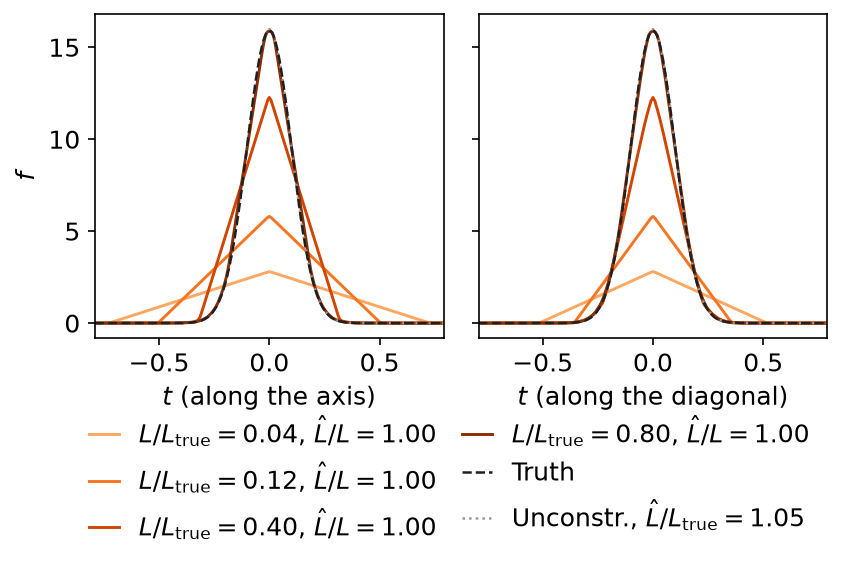

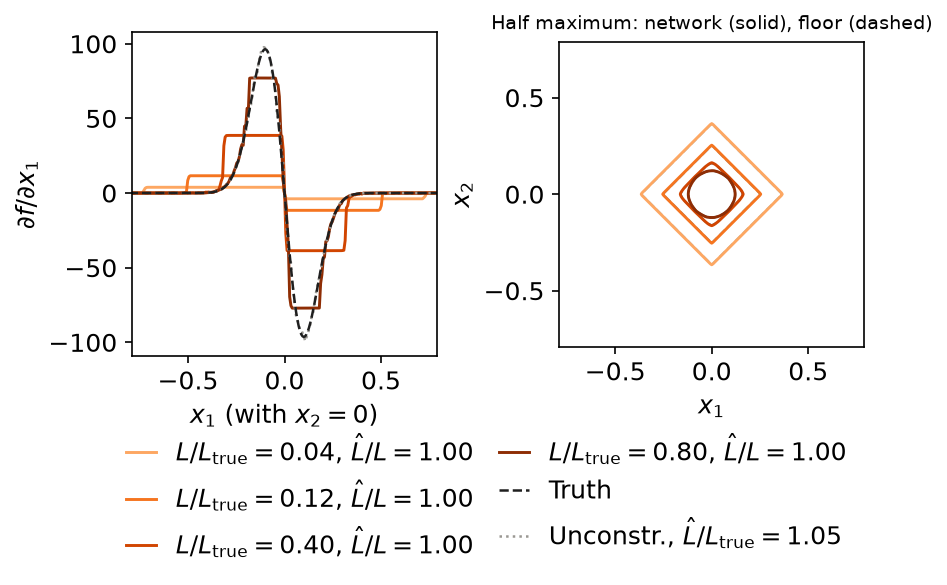

L/L_true        L_hat/L  L2 slope/L    peak: net | floor   FWHM_eq: net | floor         ISE: net | floor
    0.04   1.000 ± 0.000       1.414     2.796 |   2.817     0.5848 |   0.5813       4.9642 |     4.9637
    0.12   1.000 ± 0.000       1.414     5.803 |   5.859     0.4106 |   0.4000       2.8637 |     2.8631
    0.40   1.000 ± 0.000       1.389    12.272 |  12.384     0.2791 |   0.2774       0.5168 |     0.5158
    0.80   0.999 ± 0.001       1.158    15.879 |  15.915     0.2389 |   0.2377       0.0081 |     0.0067

Unconstrained: largest partial derivative 100.9 (L_true = 96.5), peak 15.989 (true 15.915), FWHM_eq 0.2352 (true 0.2353), ISE 1.35e-04


In [12]:
# Network fits in the same format as the floor fits, in orange (implementation) instead of blue (theory)
net_shades = plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_show)))


def largest_slope(gradients, norm):
    """Largest slope over the grid for every seed: max_x of |grad f|_inf (the networks' norm) or |grad f|_2."""
    order = np.inf if norm == "inf" else 2
    return np.linalg.norm(gradients, ord=order, axis=-1).reshape(len(gradients), -1).max(axis=1)


with plt.rc_context(REPORT_STYLE):
    # (a) Cuts along the axis and along the diagonal: mean over seeds, band = spread between seeds
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), sharey=True, gridspec_kw=dict(wspace=0.1))
    for ax, direction, truth, name in [(axs[0], AXIS_DIRECTION, truth_axis, "axis"),
                                       (axs[1], DIAGONAL_DIRECTION, truth_diagonal, "diagonal")]:
        network_lines = []
        for L, c in zip(L_show, net_shades):
            cuts = np.array([profile(axes, fit, direction, t_cut) for fit in net_fits[L]])
            ax.fill_between(t_cut, cuts.min(0), cuts.max(0), color=c, alpha=0.3, lw=0)
            L_hat = largest_slope(net_gradients[L], "inf").mean()
            line, = ax.plot(t_cut, cuts.mean(0), color=c, lw=1.4, label=rf"$L/L_\mathrm{{true}} = {L / L_true:.2f}$, $\hat{{L}}/L = {L_hat / L:.2f}$")
            network_lines.append(line)
        unc_cut = np.mean([profile(axes, fit, direction, t_cut) for fit in unc_fits], axis=0)
        unconstrained_line, = ax.plot(t_cut, unc_cut, color=C_REF, lw=1.2, ls=":",
                                      label=rf"Unconstr., $\hat{{L}}/L_\mathrm{{true}} = {largest_slope(unc_gradients, 'inf').mean() / L_true:.2f}$")
        truth_line, = ax.plot(t_cut, truth, color=C_TRUE, lw=1.2, ls="--", label="Truth")
        ax.set_xlim(-t_zoom, t_zoom)
        ax.set_xlabel(rf"$t$ (along the {name})")
    axs[0].set_ylabel(r"$f$")
    fig.legend(handles=network_lines + [truth_line, unconstrained_line], loc="upper center", bbox_to_anchor=(0.5, -0.02),
               ncol=2, handlelength=1.2, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_network_fits_cuts.pdf")
    plt.show()

    # (b) Slopes along the x_1 axis, and the half-maximum contours of the networks (mean over seeds) on top of the floors
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), gridspec_kw=dict(wspace=0.4))
    for L, c in zip(L_show, net_shades):
        axs[0].plot(axes[0], central_line(net_gradients[L][..., 0].mean(0)), color=c, lw=1.4)
    axs[0].plot(axes[0], central_line(unc_gradients[..., 0].mean(0)), color=C_REF, lw=1.2, ls=":")
    axs[0].plot(axes[0], slope_true_axis, color=C_TRUE, lw=1.2, ls="--")
    axs[0].set_xlim(-t_zoom, t_zoom)
    axs[0].set_xlabel(r"$x_1$ (with $x_2 = 0$)"); axs[0].set_ylabel(r"$\partial f/\partial x_1$")

    for L, c_floor, c_net in zip(L_show, shades, net_shades):
        axs[1].contour(axes[0], axes[1], floors[L].T, levels=[floors[L].max() / 2], colors=[c_floor], linewidths=1.0, linestyles="--")
        mean_fit = net_fits[L].mean(0)
        axs[1].contour(axes[0], axes[1], mean_fit.T, levels=[mean_fit.max() / 2], colors=[c_net], linewidths=1.4)
    axs[1].set_xlim(-t_zoom, t_zoom); axs[1].set_ylim(-t_zoom, t_zoom)
    axs[1].set_aspect("equal")
    axs[1].set_xlabel(r"$x_1$"); axs[1].set_ylabel(r"$x_2$")
    axs[1].set_title("Half maximum: network (solid), floor (dashed)", fontsize=9)
    fig.legend(handles=network_lines + [truth_line, unconstrained_line], loc="upper center", bbox_to_anchor=(0.5, -0.02),
               ncol=2, handlelength=1.2, columnspacing=1.0)
    fig.savefig(f"{PLOT_DIR}/gaussian_network_slopes_and_contours.pdf")
    plt.show()

# --- Table: network (mean ± std over seeds) against the floor, all on the full evaluation grid
print(f"{'L/L_true':>8} {'L_hat/L':>14} {'L2 slope/L':>11} {'peak: net | floor':>20} {'FWHM_eq: net | floor':>22} {'ISE: net | floor':>24}")
for L in L_show:
    L_hat = largest_slope(net_gradients[L], "inf") / L
    L_hat_2 = largest_slope(net_gradients[L], "2") / L
    peaks = net_fits[L].reshape(len(SEEDS_NET), -1).max(axis=1)
    fwhm_net = np.array([fwhm_equivalent(f, axes) for f in net_fits[L]])
    ise = np.array([grid_integral((f - y_grid) ** 2, axes) for f in net_fits[L]])
    print(f"{L / L_true:8.2f} {L_hat.mean():7.3f} ± {L_hat.std():.3f} {L_hat_2.mean():11.3f}"
          f"   {peaks.mean():7.3f} | {floors[L].max():7.3f}"
          f"   {fwhm_net.mean():8.4f} | {fwhm_equivalent(floors[L], axes):8.4f}"
          f"   {ise.mean():10.4f} | {grid_integral((floors[L] - y_grid) ** 2, axes):10.4f}")

ise_unc = np.array([grid_integral((f - y_grid) ** 2, axes) for f in unc_fits])
print(f"\nUnconstrained: largest partial derivative {largest_slope(unc_gradients, 'inf').mean():.1f} (L_true = {L_true:.1f}), "
      f"peak {unc_fits.reshape(len(SEEDS_NET), -1).max(axis=1).mean():.3f} (true {peak_true:.3f}), "
      f"FWHM_eq {np.mean([fwhm_equivalent(f, axes) for f in unc_fits]):.4f} (true {fwhm_equivalent(y_grid, axes):.4f}), ISE {ise_unc.mean():.2e}")

# Added noise response
The 2D version of the sine-wave test. The target is a wide Gaussian with plane waves on top,
$$
y(x) = f(x) + \sum_j A_j \sin(k_j \cdot x).
$$
In the networks' norm, a plane wave needs the slope $A\,\|k\|_\infty = A \max_i |k_i|$. In 1D this is $A\omega$. A wave along an axis and a wave along the diagonal with the same $\|k\|_\infty$ need the same budget, although the diagonal wave has the shorter wavelength. If the bound is what removes the waves, the fraction that survives should depend only on $A\|k\|_\infty / L$, not on $A\|k\|_2 / L$. This is a direct test of which norm the networks are bounded in.

The Gaussian is wider than in the floor sections, $\sigma = 1$ on $[-5, 5)^2$. Its peak, 0.16, is close to that of the 1D noise test (0.2), and it needs a much smaller slope than any of the waves. The wave vectors are whole numbers of periods across the grid, so every wave sits exactly on one Fourier mode.

In [13]:
# Plane-wave noise on top of a wide 2D Gaussian
N_NOISE = 40 if QUICK else 160                # points per axis
X_MIN, X_MAX = -5, 5
SIGMA_NOISE = 1.0
AMPLITUDES = [0.5, 0.3, 0.7]                  # amplitude A of each wave, as in the 1D notebook
MODES = [(3, 0), (5, 5), (0, 16)]             # whole number of periods along each axis: along x_1, diagonal, along x_2
WAVEVECTORS = [wavevector(m, X_MAX - X_MIN) for m in MODES]

# Periodic grid (no double end point), the clean Gaussian, the noise and the noisy Gaussian
axes_noise, X_noise = make_grid((X_MAX - X_MIN) / 2, N_NOISE, DIM, endpoint=False)
gaussian = gaussian_nd(X_noise, np.zeros(DIM), isotropic_cov(SIGMA_NOISE, DIM))
noise = plane_wave_noise(X_noise, AMPLITUDES, WAVEVECTORS)
noisy_gaussian = gaussian + noise

L_true_noise_gaussian = isotropic_lipschitz_constant(SIGMA_NOISE, DIM)
print(f"Largest slope of the Gaussian: {L_true_noise_gaussian:.4f}")
for A, k in zip(AMPLITUDES, WAVEVECTORS):
    print(f"Wave with k = ({k[0]:5.2f}, {k[1]:5.2f}): amplitude {A}, needs slope A |k|_inf = {plane_wave_slope(A, k):.3f} "
          f"(Euclidean A |k|_2 = {A * np.linalg.norm(k):.3f})")

Largest slope of the Gaussian: 0.0965
Wave with k = ( 1.88,  0.00): amplitude 0.5, needs slope A |k|_inf = 0.942 (Euclidean A |k|_2 = 0.942)
Wave with k = ( 3.14,  3.14): amplitude 0.3, needs slope A |k|_inf = 0.942 (Euclidean A |k|_2 = 1.333)
Wave with k = ( 0.00, 10.05): amplitude 0.7, needs slope A |k|_inf = 7.037 (Euclidean A |k|_2 = 7.037)


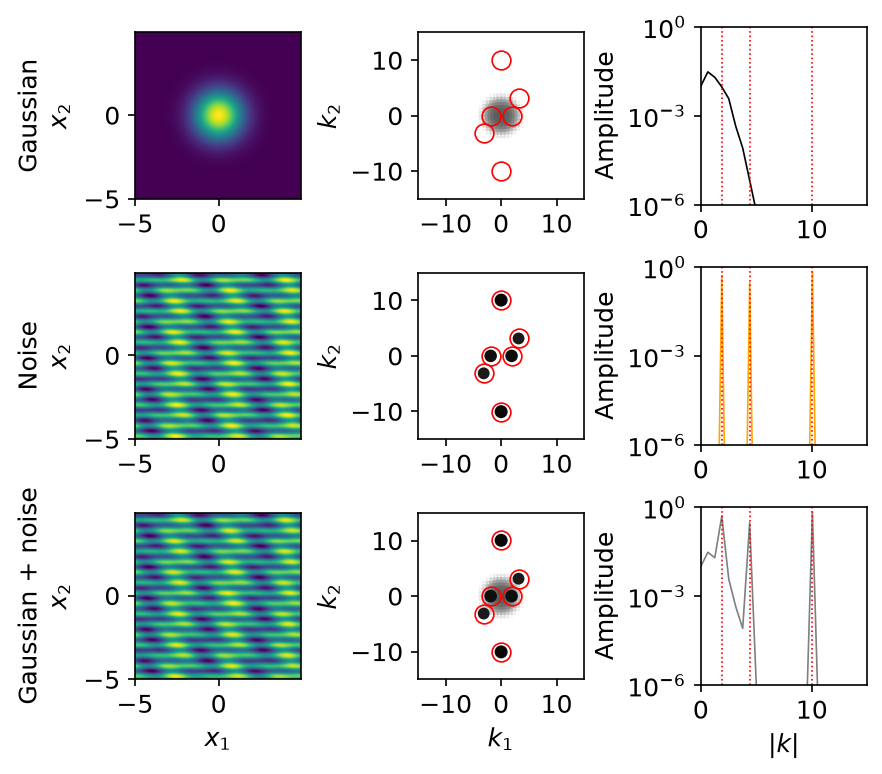

In [14]:
# Report figure of the generated data: the Gaussian, the noise and the Gaussian with noise (rows).
# Columns: the function, its 2D Fourier spectrum, and the radial spectrum (amplitude against |k|).
# Used for both the plane-wave noise and the white noise.

def plot_noise_inputs(axes_grid, clean, noise_values, noisy, file_name, log_k, k_max, wavevectors=None):
    rows = [clean, noise_values, noisy]
    row_names = ["Gaussian", "Noise", "Gaussian + noise"]
    row_colors = ["black", "orange", "grey"]
    extent = [axes_grid[0][0], axes_grid[0][-1], axes_grid[1][0], axes_grid[1][-1]]

    with plt.rc_context(REPORT_STYLE):
        fig, axs = plt.subplots(3, 3, figsize=(6.3, 1.9 * 3), gridspec_kw=dict(hspace=0.35, wspace=0.7))
        for i, f in enumerate(rows):
            # --- The function
            image = axs[i, 0].imshow(f.T, origin="lower", extent=extent, cmap="viridis")
            axs[i, 0].set_ylabel(f"{row_names[i]}\n" + r"$x_2$")

            # --- 2D spectrum: one dot per Fourier mode, darker = larger amplitude (log scale). Drawn as dots, since a
            # single mode would only be one pixel wide in an image. The strongest modes are drawn last, on top.
            K, coefficients = fourier_modes(axes_grid, f)
            shown = np.all(np.abs(K) <= k_max, axis=-1)
            log_amplitude = np.log10(np.maximum(2 * coefficients[shown], 1e-8))
            order = np.argsort(log_amplitude)
            dot_size = 2 + 40 * np.clip((log_amplitude[order] + 6) / 6, 0, 1) ** 3   # strong modes as large dots
            axs[i, 1].scatter(K[shown][order, 0], K[shown][order, 1], c=log_amplitude[order], s=dot_size, vmin=-6, vmax=0,
                              cmap="Greys", linewidths=0)
            axs[i, 1].set_xlim(-k_max, k_max); axs[i, 1].set_ylim(-k_max, k_max)
            axs[i, 1].set_aspect("equal")
            axs[i, 1].set_ylabel(r"$k_2$")

            # --- Radial spectrum
            k_radial, amplitude_radial = radial_spectrum(axes_grid, f)
            axs[i, 2].plot(k_radial, amplitude_radial, color=row_colors[i], lw=0.8)
            if log_k:
                axs[i, 2].set_xscale("log")
            else:
                axs[i, 2].set_xlim(0, k_max)
            axs[i, 2].set_yscale("log")
            axs[i, 2].set_ylim(1e-6, 1)
            axs[i, 2].set_ylabel("Amplitude")

            if wavevectors is not None:   # mark the waves, at +k and -k in the 2D spectrum
                for k in wavevectors:
                    axs[i, 1].plot([k[0], -k[0]], [k[1], -k[1]], "o", mfc="none", color="red", ms=9, mew=0.8)
                    axs[i, 2].axvline(np.linalg.norm(k), color="red", ls=":", lw=0.8)

        axs[-1, 0].set_xlabel(r"$x_1$")
        axs[-1, 1].set_xlabel(r"$k_1$")
        axs[-1, 2].set_xlabel(r"$|k|$")
        fig.align_ylabels(axs[:, 0])
        fig.savefig(file_name)
        plt.show()


plot_noise_inputs(axes_noise, gaussian, noise, noisy_gaussian, f"{PLOT_DIR}/sine_noise_input_and_spectra.pdf",
                  log_k=False, k_max=15, wavevectors=WAVEVECTORS)

### Training Lipschitz networks on the plane-wave noise

In [15]:
# Training Lipschitz networks on the noisy Gaussian. All networks of one section are trained in parallel.
L_VALUES = [0.1, 0.25, 0.5, 1.0]   # the Gaussian needs 0.1, the waves need about 1 to 7
SEEDS = [0, 1] if QUICK else [0, 1, 2]
HIDDEN_DIM = 64
N_GROUPS = 8
DEPTH = 5
STEPS = 100 if QUICK else 6000
LEARNING_RATE = 3e-3


def noise_jobs(x, y, L_values, seeds):
    """Training jobs for every L and seed, followed by the unconstrained reference for every seed."""
    jobs = []
    for L in L_values:
        for seed in seeds:
            jobs.append(dict(kind="lipschitz", seed=seed, steps=STEPS, lr=LEARNING_RATE, x=x, y=y,
                             model_kwargs=dict(input_dim=DIM, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS,
                                               depth=DEPTH, lipschitz_bound=L)))
    for seed in seeds:
        jobs.append(dict(kind="unconstrained", seed=seed, steps=STEPS, lr=LEARNING_RATE, x=x, y=y,
                         model_kwargs=dict(input_dim=DIM, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)))
    return jobs


def collect_predictions(results, L_values, seeds, shape):
    """predictions[L][seed] and predictions_unconstrained[seed] as grid arrays, in the order of noise_jobs."""
    results = iter(results)
    predictions = {L: {seed: next(results)["prediction"].reshape(shape) for seed in seeds} for L in L_values}
    predictions_unconstrained = {seed: next(results)["prediction"].reshape(shape) for seed in seeds}
    return predictions, predictions_unconstrained


x_noise = X_noise.reshape(-1, DIM)
results = train_many(noise_jobs(x_noise, noisy_gaussian.ravel(), L_VALUES, SEEDS))
predictions, predictions_unconstrained = collect_predictions(results, L_VALUES, SEEDS, gaussian.shape)

for name, runs in [*[(f"L = {L}", predictions[L]) for L in L_VALUES], ("Unconstrained", predictions_unconstrained)]:
    for seed, prediction in runs.items():
        print(f"{name}, seed {seed}: MSE to the noisy data = {np.mean((prediction - noisy_gaussian) ** 2):.2e}, "
              f"MSE to the clean Gaussian = {np.mean((prediction - gaussian) ** 2):.2e}")

L = 0.1, seed 0: MSE to the noisy data = 3.76e-01, MSE to the clean Gaussian = 7.99e-03
L = 0.1, seed 1: MSE to the noisy data = 3.76e-01, MSE to the clean Gaussian = 7.92e-03
L = 0.1, seed 2: MSE to the noisy data = 3.76e-01, MSE to the clean Gaussian = 7.97e-03
L = 0.25, seed 0: MSE to the noisy data = 3.34e-01, MSE to the clean Gaussian = 2.43e-02
L = 0.25, seed 1: MSE to the noisy data = 3.36e-01, MSE to the clean Gaussian = 2.37e-02
L = 0.25, seed 2: MSE to the noisy data = 3.35e-01, MSE to the clean Gaussian = 2.37e-02
L = 0.5, seed 0: MSE to the noisy data = 2.92e-01, MSE to the clean Gaussian = 6.21e-02
L = 0.5, seed 1: MSE to the noisy data = 2.96e-01, MSE to the clean Gaussian = 6.21e-02
L = 0.5, seed 2: MSE to the noisy data = 2.94e-01, MSE to the clean Gaussian = 6.33e-02
L = 1.0, seed 0: MSE to the noisy data = 2.56e-01, MSE to the clean Gaussian = 1.16e-01
L = 1.0, seed 1: MSE to the noisy data = 2.58e-01, MSE to the clean Gaussian = 1.15e-01
L = 1.0, seed 2: MSE to the n

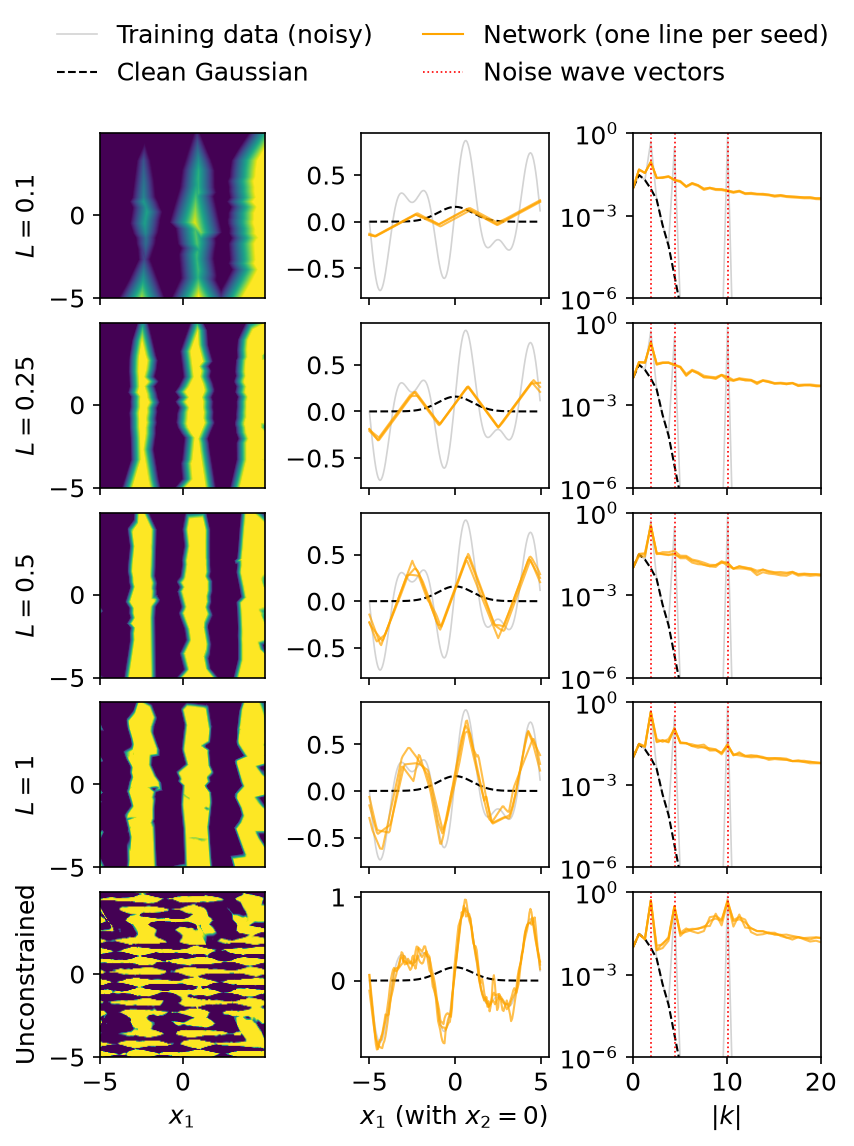

In [16]:
# Report figure: one row per network. Columns: the fit (seed 0), a cut along x_1 through the centre, and the radial spectrum

def plot_noise_fits(axes_grid, clean, noisy, predictions, predictions_unconstrained, L_values, file_name, log_k,
                    k_max=None, wavevectors=None):
    rows = [(f"$L = {L:g}$", predictions[L]) for L in L_values] + [("Unconstrained", predictions_unconstrained)]
    extent = [axes_grid[0][0], axes_grid[0][-1], axes_grid[1][0], axes_grid[1][-1]]
    k_noisy, amplitude_noisy = radial_spectrum(axes_grid, noisy)
    k_clean, amplitude_clean = radial_spectrum(axes_grid, clean)

    with plt.rc_context(REPORT_STYLE):
        fig, axs = plt.subplots(len(rows), 3, figsize=(6.3, 1.6 * len(rows)), sharex="col",
                                gridspec_kw=dict(hspace=0.15, wspace=0.45))
        for i, (name, runs) in enumerate(rows):
            first = next(iter(runs.values()))
            axs[i, 0].imshow(first.T, origin="lower", extent=extent, cmap="viridis",
                             vmin=clean.min(), vmax=clean.max())   # same colour scale as the clean Gaussian
            axs[i, 0].set_ylabel(name)

            axs[i, 1].plot(axes_grid[0], central_line(noisy), color="lightgrey", lw=0.8)
            axs[i, 1].plot(axes_grid[0], central_line(clean), color="black", lw=1.0, ls="--")
            for prediction in runs.values():
                axs[i, 1].plot(axes_grid[0], central_line(prediction), color="orange", alpha=0.7, lw=1.0)

            axs[i, 2].plot(k_noisy, amplitude_noisy, color="lightgrey", lw=0.8)
            axs[i, 2].plot(k_clean, amplitude_clean, color="black", lw=1.0, ls="--")
            for prediction in runs.values():
                axs[i, 2].plot(*radial_spectrum(axes_grid, prediction), color="orange", alpha=0.7, lw=1.0)
            if wavevectors is not None:
                for k in wavevectors:
                    axs[i, 2].axvline(np.linalg.norm(k), color="red", ls=":", lw=0.8)
            axs[i, 2].set_yscale("log")
            axs[i, 2].set_ylim(1e-6, 1)
            if log_k:
                axs[i, 2].set_xscale("log")
            else:
                axs[i, 2].set_xlim(0, k_max)

        axs[-1, 0].set_xlabel(r"$x_1$")
        axs[-1, 1].set_xlabel(r"$x_1$ (with $x_2 = 0$)")
        axs[-1, 2].set_xlabel(r"$|k|$")
        legend_lines = [plt.Line2D([], [], color="lightgrey", lw=0.8), plt.Line2D([], [], color="black", lw=1.0, ls="--"),
                        plt.Line2D([], [], color="orange", lw=1.0)]
        legend_labels = ["Training data (noisy)", "Clean Gaussian", "Network (one line per seed)"]
        if wavevectors is not None:
            legend_lines.append(plt.Line2D([], [], color="red", ls=":", lw=0.8))
            legend_labels.append("Noise wave vectors")
        fig.legend(legend_lines, legend_labels, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=2)
        fig.savefig(file_name)
        plt.show()


plot_noise_fits(axes_noise, gaussian, noisy_gaussian, predictions, predictions_unconstrained, L_VALUES,
                f"{PLOT_DIR}/sine_noise_fits_and_spectra.pdf", log_k=False, k_max=20, wavevectors=WAVEVECTORS)

Fraction of each wave that survives (mean ± std over seeds)
L = 0.1:
   k = ( 1.88,  0.00), A|k|_inf/L =  9.42: 0.17 ± 0.00
   k = ( 3.14,  3.14), A|k|_inf/L =  9.42: 0.01 ± 0.00
   k = ( 0.00, 10.05), A|k|_inf/L = 70.37: 0.01 ± 0.00
L = 0.25:
   k = ( 1.88,  0.00), A|k|_inf/L =  3.77: 0.39 ± 0.00
   k = ( 3.14,  3.14), A|k|_inf/L =  3.77: 0.02 ± 0.00
   k = ( 0.00, 10.05), A|k|_inf/L = 28.15: 0.01 ± 0.00
L = 0.5:
   k = ( 1.88,  0.00), A|k|_inf/L =  1.88: 0.68 ± 0.01
   k = ( 3.14,  3.14), A|k|_inf/L =  1.88: 0.07 ± 0.02
   k = ( 0.00, 10.05), A|k|_inf/L = 14.07: 0.02 ± 0.00
L = 1.0:
   k = ( 1.88,  0.00), A|k|_inf/L =  0.94: 0.90 ± 0.00
   k = ( 3.14,  3.14), A|k|_inf/L =  0.94: 0.35 ± 0.01
   k = ( 0.00, 10.05), A|k|_inf/L =  7.04: 0.03 ± 0.00
Unconstrained:
   k = ( 1.88,  0.00): 1.00 ± 0.00
   k = ( 3.14,  3.14): 1.01 ± 0.00
   k = ( 0.00, 10.05): 0.66 ± 0.05

MSE to the clean Gaussian (noisy data itself: 4.15e-01) and noise removed
   L = 0.1       : MSE 7.96e-03 ± 2.9e-05, noise

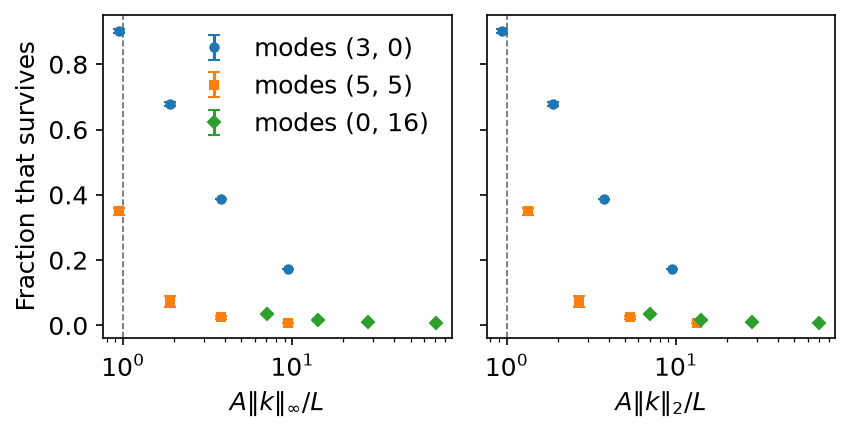

In [17]:
# Evaluation: how much of each wave survives in the network output, and how close the networks get to the clean Gaussian

def surviving_fractions(runs, A, k):
    """Amplitude of the wave in every prediction divided by its amplitude in the data."""
    return np.array([mode_amplitude_nd(axes_noise, prediction, k) / A for prediction in runs.values()])


print("Fraction of each wave that survives (mean ± std over seeds)")
for L in L_VALUES:
    print(f"L = {L}:")
    for A, k in zip(AMPLITUDES, WAVEVECTORS):
        fractions = surviving_fractions(predictions[L], A, k)
        print(f"   k = ({k[0]:5.2f}, {k[1]:5.2f}), A|k|_inf/L = {plane_wave_slope(A, k) / L:5.2f}: {fractions.mean():.2f} ± {fractions.std():.2f}")
print("Unconstrained:")
for A, k in zip(AMPLITUDES, WAVEVECTORS):
    fractions = surviving_fractions(predictions_unconstrained, A, k)
    print(f"   k = ({k[0]:5.2f}, {k[1]:5.2f}): {fractions.mean():.2f} ± {fractions.std():.2f}")

# Denoising: MSE against the CLEAN Gaussian, and the share of the noise energy removed
print(f"\nMSE to the clean Gaussian (noisy data itself: {np.mean(noise ** 2):.2e}) and noise removed")
for name, runs in [*[(f"L = {L}", predictions[L]) for L in L_VALUES], ("Unconstrained", predictions_unconstrained)]:
    mse_clean = [np.mean((prediction - gaussian) ** 2) for prediction in runs.values()]
    removed = [100 * noise_removed(prediction, gaussian, noise) for prediction in runs.values()]
    print(f"   {name:14s}: MSE {np.mean(mse_clean):.2e} ± {np.std(mse_clean):.1e}, noise removed {np.mean(removed):5.1f} ± {np.std(removed):.1f} %")

# Summary plot: fraction that survives against the slope the wave needs relative to the budget.
# Left in the networks' norm (A |k|_inf / L), right in the Euclidean norm (A |k|_2 / L). If the networks are bounded in
# the L1 norm, the waves fall on one curve on the left, and the diagonal wave is shifted on the right.
markers = ["o", "s", "D"]
with plt.rc_context(REPORT_STYLE):
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), sharey=True, gridspec_kw=dict(wspace=0.1))
    for A, k, m, marker in zip(AMPLITUDES, WAVEVECTORS, MODES, markers):
        mean_fractions = [surviving_fractions(predictions[L], A, k).mean() for L in L_VALUES]
        std_fractions = [surviving_fractions(predictions[L], A, k).std() for L in L_VALUES]
        for ax, slope in [(axs[0], plane_wave_slope(A, k)), (axs[1], A * np.linalg.norm(k))]:
            ax.errorbar(slope / np.array(L_VALUES), mean_fractions, yerr=std_fractions, fmt=marker, capsize=3,
                        ms=4, label=f"modes {m}")
    for ax, label in [(axs[0], r"$A\|k\|_\infty / L$"), (axs[1], r"$A\|k\|_2 / L$")]:
        ax.axvline(1, color=C_MUTED, ls="--", lw=0.8)
        ax.set_xscale("log")
        ax.set_xlabel(label)
    axs[0].set_ylabel("Fraction that survives")
    axs[0].legend()
    fig.savefig(f"{PLOT_DIR}/sine_noise_surviving_fraction.pdf")
    plt.show()

In [18]:
# Investigating the effect of the Lipschitz bound on the noise removal and the accuracy.
# This cell only trains and stores the predictions. The measures are calculated in the plotting cell below.
L_RATIO = np.logspace(-1.5, 0, 3 if QUICK else 12)   # L / L_max

L_noisy = grid_lipschitz_estimate(noisy_gaussian, axes_noise)   # largest partial derivative of the noisy data on the grid
L_max = max(L_true_noise_gaussian, L_noisy)
print(f"Largest slope of the Gaussian: {L_true_noise_gaussian:.4f}, of the noisy data: {L_noisy:.4f}")

L_scan_noise = L_RATIO * L_max
results = train_many(noise_jobs(x_noise, noisy_gaussian.ravel(), L_scan_noise, SEEDS))
predictions_scan, predictions_scan_unconstrained = collect_predictions(results, L_scan_noise, SEEDS, gaussian.shape)

Largest slope of the Gaussian: 0.0965, of the noisy data: 7.6160


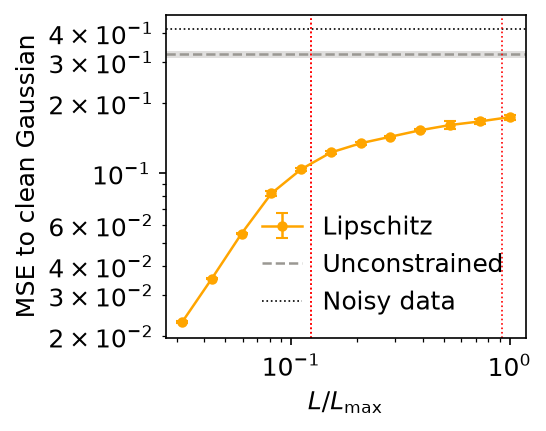

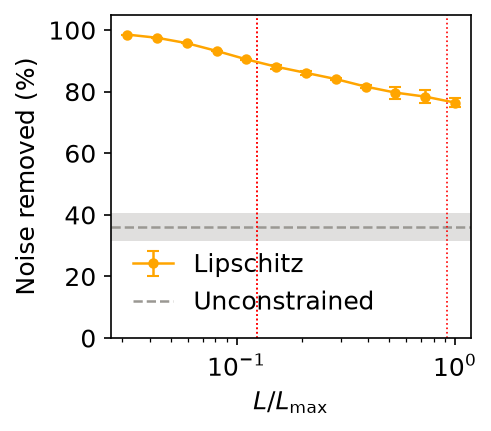

In [19]:
# MSE to the clean Gaussian and the noise removed as a function of L, with the unconstrained network as reference.
# Error bars: the spread (std) over the seeds. Dotted red lines: where each wave starts to be clipped, A |k|_inf / L_max.

def mean_std(values):
    return np.mean(values), np.std(values)


measures = {
    "mse": (lambda p: np.mean((p - gaussian) ** 2), "MSE to clean Gaussian", "sine_noise_mse_vs_L.pdf"),
    "removed": (lambda p: 100 * noise_removed(p, gaussian, noise), "Noise removed (%)", "sine_noise_removed_vs_L.pdf"),
}

with plt.rc_context(REPORT_STYLE):
    for name, (measure, label, file_name) in measures.items():
        scan_values = np.array([mean_std([measure(p) for p in predictions_scan[L].values()]) for L in L_scan_noise])
        unc_mean, unc_std = mean_std([measure(p) for p in predictions_scan_unconstrained.values()])

        fig, ax = plt.subplots(figsize=PANEL_SIZE)
        lipschitz_line = ax.errorbar(L_RATIO, scan_values[:, 0], yerr=scan_values[:, 1], fmt="o-", color="orange",
                                     lw=1.2, markersize=4, capsize=3, label="Lipschitz")
        unconstrained_line = ax.axhline(unc_mean, color=C_REF, lw=1.2, ls="--", label="Unconstrained")
        ax.axhspan(unc_mean - unc_std, unc_mean + unc_std, color=C_REF, alpha=0.3, lw=0)
        handles = [lipschitz_line, unconstrained_line]
        if name == "mse":
            handles.append(ax.axhline(np.mean(noise ** 2), color="black", lw=0.8, ls=":", label="Noisy data"))
            ax.set_yscale("log")
        else:
            ax.set_ylim(0, 105)
        for A, k in zip(AMPLITUDES, WAVEVECTORS):
            ax.axvline(plane_wave_slope(A, k) / L_max, color="red", ls=":", lw=0.8)
        ax.set_xscale("log")
        ax.set_xlabel(r"$L / L_\mathrm{max}$")
        ax.set_ylabel(label)
        ax.legend(handles=handles)
        fig.savefig(f"{PLOT_DIR}/{file_name}")
        plt.show()

# White noise response
The same set-up as the plane-wave section: the same Gaussian ($\sigma = 1$), grid, Lipschitz constants, seeds and networks. Only the noise is different. Every grid point gets its own independent random noise, with the same power (mean squared noise) as the plane waves, so the two sections can be compared directly.

White noise spreads its energy evenly over all wave vectors. Most of it is very fast and needs slopes of roughly $\sqrt{2}\,\sigma_\text{noise}/\Delta x$, far above any $L$ used. We therefore expect the Lipschitz networks to remove most of it. The evaluation is the same as in 1D. We measure the fraction of the noise kept in bands of $|k|$, and how much of the actual noise pattern the network copies.

Noise standard deviation: 0.6442 (mean squared noise 4.11e-01)
Typical slope of the noise between neighbouring points: 14.6
Largest slope of the noisy data: 62.1


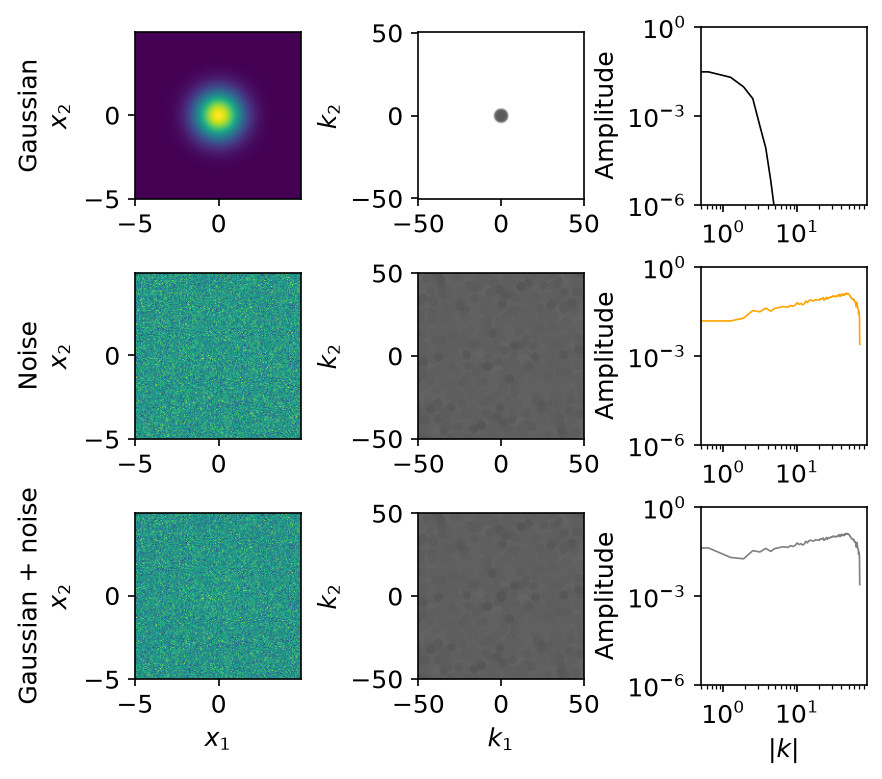

In [20]:
# White noise on top of the same Gaussian, with the same power as the plane waves
NOISE_STD = np.sqrt(np.mean(noise ** 2))
NOISE_SEED = 0
rng = np.random.default_rng(NOISE_SEED)
white_noise = NOISE_STD * rng.standard_normal(gaussian.shape)
gaussian_white_noisy = gaussian + white_noise

dx_noise = grid_spacing(axes_noise)[0]
print(f"Noise standard deviation: {NOISE_STD:.4f} (mean squared noise {np.mean(white_noise ** 2):.2e})")
print(f"Typical slope of the noise between neighbouring points: {np.sqrt(2) * NOISE_STD / dx_noise:.1f}")
print(f"Largest slope of the noisy data: {grid_lipschitz_estimate(gaussian_white_noisy, axes_noise):.1f}")

plot_noise_inputs(axes_noise, gaussian, white_noise, gaussian_white_noisy, f"{PLOT_DIR}/white_noise_input_and_spectra.pdf",
                  log_k=True, k_max=np.pi / dx_noise)

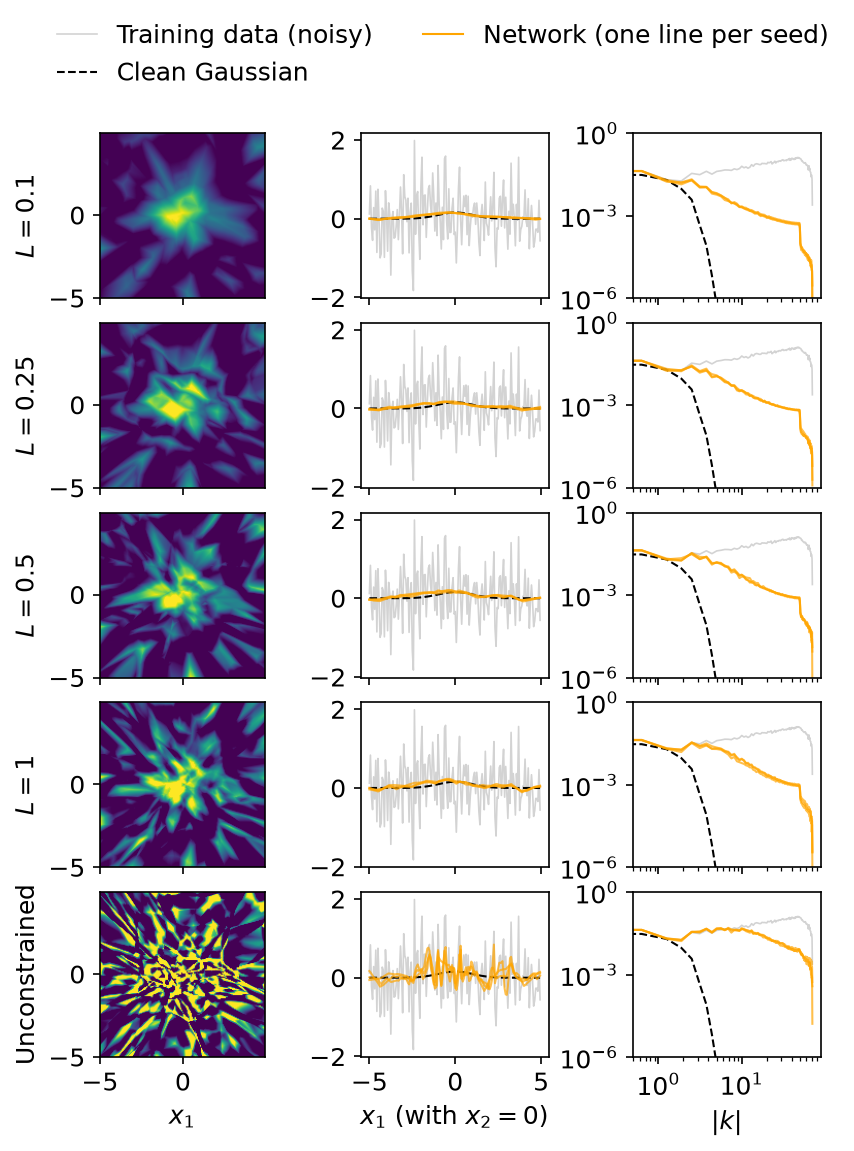

In [21]:
# Training on the white noise (same networks and settings as the plane-wave section)
results = train_many(noise_jobs(x_noise, gaussian_white_noisy.ravel(), L_VALUES, SEEDS))
predictions_white, predictions_white_unconstrained = collect_predictions(results, L_VALUES, SEEDS, gaussian.shape)

plot_noise_fits(axes_noise, gaussian, gaussian_white_noisy, predictions_white, predictions_white_unconstrained, L_VALUES,
                f"{PLOT_DIR}/white_noise_fits_and_spectra.pdf", log_k=True)

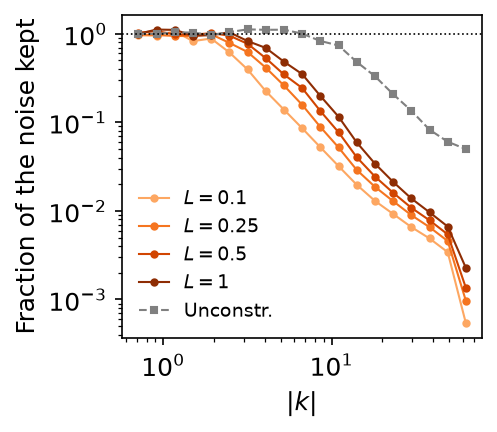

Network              noise removed    remaining error / noise
L = 0.1             100.0 ±  0.0 %           0.002 ± 0.000
L = 0.25            100.0 ±  0.0 %           0.003 ± 0.000
L = 0.5             100.0 ±  0.0 %           0.005 ± 0.000
L = 1.0             100.0 ±  0.0 %           0.007 ± 0.001
Unconstrained        99.6 ±  0.0 %           0.058 ± 0.002


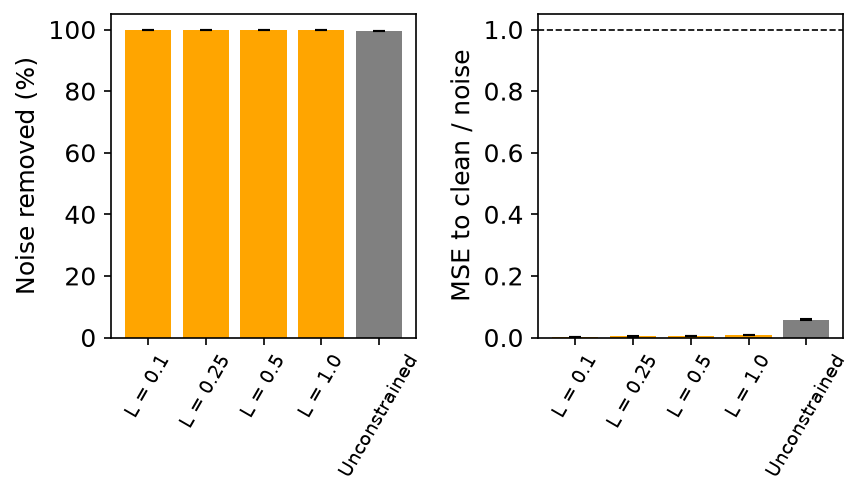

In [22]:
# Which wave vectors of the noise does each network keep? Fraction of the noise amplitude left in the output,
# in logarithmic bands of |k|:  fraction kept = sqrt( power of (output - clean Gaussian) / power of the noise ).
# The error of the output also contains any distortion of the Gaussian, which only matters at the smallest |k|.
dk = 2 * np.pi / (X_MAX - X_MIN)
k_largest = np.sqrt(DIM) * np.pi / dx_noise
band_edges = np.logspace(np.log10(dk), np.log10(k_largest * 1.001), 9 if QUICK else 20)
noise_band_power = band_power(axes_noise, white_noise, band_edges[:-1], band_edges[1:])
non_empty = noise_band_power > 0
band_lower, band_upper = band_edges[:-1][non_empty], band_edges[1:][non_empty]
band_centres = np.sqrt(band_lower * band_upper)


def fraction_kept_per_band(prediction):
    return np.sqrt(band_power(axes_noise, prediction - gaussian, band_lower, band_upper) / noise_band_power[non_empty])


with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    for L, color in zip(L_VALUES, plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_VALUES)))):
        ax.plot(band_centres, np.mean([fraction_kept_per_band(p) for p in predictions_white[L].values()], axis=0),
                "o-", color=color, ms=3, lw=1.0, label=f"$L = {L:g}$")
    ax.plot(band_centres, np.mean([fraction_kept_per_band(p) for p in predictions_white_unconstrained.values()], axis=0),
            "s--", color="grey", ms=3, lw=1.0, label="Unconstr.")
    ax.axhline(1, color="black", ls=":", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$|k|$"); ax.set_ylabel("Fraction of the noise kept")
    ax.legend(fontsize=9)
    fig.savefig(f"{PLOT_DIR}/white_noise_fraction_kept.pdf")
    plt.show()

# Noise removed and remaining error relative to the noise (mean ± std over seeds)
names, removed_mean, removed_std, error_mean, error_std = [], [], [], [], []
for name, runs in [*[(f"L = {L}", predictions_white[L]) for L in L_VALUES], ("Unconstrained", predictions_white_unconstrained)]:
    removed = [100 * noise_removed(p, gaussian, white_noise) for p in runs.values()]
    error = [np.mean((p - gaussian) ** 2) / np.mean(white_noise ** 2) for p in runs.values()]
    names.append(name)
    removed_mean.append(np.mean(removed)); removed_std.append(np.std(removed))
    error_mean.append(np.mean(error)); error_std.append(np.std(error))

print(f"{'Network':15s} {'noise removed':>18s} {'remaining error / noise':>26s}")
for i in range(len(names)):
    print(f"{names[i]:15s} {removed_mean[i]:9.1f} ± {removed_std[i]:4.1f} % {error_mean[i]:15.3f} ± {error_std[i]:.3f}")

with plt.rc_context(REPORT_STYLE):
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), gridspec_kw=dict(wspace=0.4))
    bar_colors = ["orange"] * len(L_VALUES) + ["grey"]
    axs[0].bar(names, removed_mean, yerr=removed_std, capsize=3, color=bar_colors)
    axs[0].set_ylabel("Noise removed (%)")
    axs[0].set_ylim(0, 105)
    axs[1].bar(names, error_mean, yerr=error_std, capsize=3, color=bar_colors)
    axs[1].axhline(1, color="black", ls="--", lw=0.8)
    axs[1].set_ylabel("MSE to clean / noise")
    for ax in axs:
        ax.tick_params(axis="x", rotation=60, labelsize=9)
    fig.savefig(f"{PLOT_DIR}/white_noise_removed.pdf")
    plt.show()

In [24]:
# Investigating the effect of the Lipschitz bound on the white noise removal and the accuracy (as for the plane waves).
# This cell only trains and stores the predictions. The measures are calculated in the plotting cell below.
# The slope of the Gaussian and the slope of the noisy data are several decades apart, so the scan is logarithmic in L
# itself: from below the slope of the Gaussian (where the bound also cuts into the Gaussian) to above the slope of the
# noisy data (where the bound no longer limits anything), with many points in between.
L_gauss_white = L_true_noise_gaussian                                        # same Gaussian as the plane-wave section
L_noisy_white = grid_lipschitz_estimate(gaussian_white_noisy, axes_noise)    # largest partial derivative of the noisy data
L_max_white = max(L_gauss_white, L_noisy_white)
print(f"Largest slope of the Gaussian: {L_gauss_white:.4f}, of the noisy data: {L_noisy_white:.1f}")

N_SCAN_WHITE = 3 if QUICK else 20                 # number of L values
L_LOWEST_WHITE = 0.5 * L_gauss_white              # at least one point below the slope of the Gaussian
L_HIGHEST_WHITE = 2.0 * L_noisy_white             # at least one point above the slope of the noisy data
L_scan_white = np.logspace(np.log10(L_LOWEST_WHITE), np.log10(L_HIGHEST_WHITE), N_SCAN_WHITE)
L_RATIO_WHITE = L_scan_white / L_max_white        # the same values relative to L_max, used on the x axis of the plots

results = train_many(noise_jobs(x_noise, gaussian_white_noisy.ravel(), L_scan_white, SEEDS))
predictions_scan_white, predictions_scan_white_unconstrained = collect_predictions(results, L_scan_white, SEEDS,
                                                                                   gaussian.shape)


Largest slope of the Gaussian: 0.0965, of the noisy data: 62.1


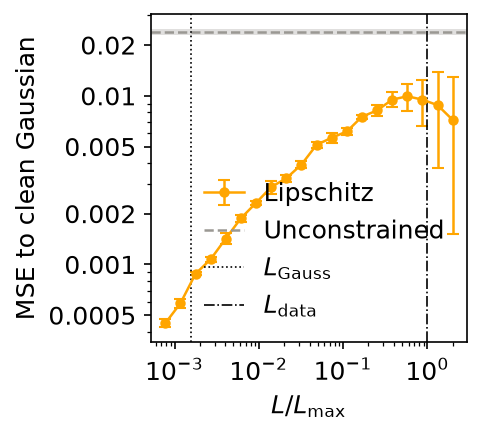

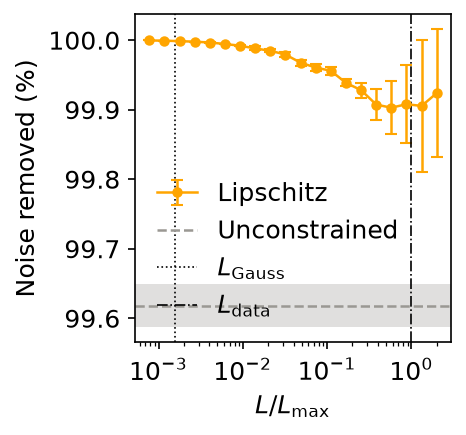

In [25]:
# MSE to the clean Gaussian and the noise removed as a function of L for the white noise, with the unconstrained network
# as reference. Error bars: the spread (std) over the seeds. Dotted line: the slope of the Gaussian (below it the bound
# also cuts into the Gaussian). Dash-dotted line: the slope of the noisy data (above it the bound limits nothing).
# The two plots sit side by side in the report, so they get a fixed size and fixed margins, and are saved without the
# tight cropping (which would make the plot with the wider tick labels a different size in LaTeX).
import matplotlib.ticker
SCAN_SIZE = PANEL_SIZE
SCAN_MARGINS = dict(left=0.28, right=0.96, top=0.96, bottom=0.18)

# MSE to the clean Gaussian and noise removed (in %) for every L: mean and spread over the seeds
mse_white_mean, mse_white_std = [], []
removed_white_mean, removed_white_std = [], []
for L in L_scan_white:
    mse = [np.mean((p - gaussian) ** 2) for p in predictions_scan_white[L].values()]
    removed = [100 * noise_removed(p, gaussian, white_noise) for p in predictions_scan_white[L].values()]
    mse_white_mean.append(np.mean(mse)); mse_white_std.append(np.std(mse))
    removed_white_mean.append(np.mean(removed)); removed_white_std.append(np.std(removed))

# The same for the unconstrained network (one value each, it has no L)
mse = [np.mean((p - gaussian) ** 2) for p in predictions_scan_white_unconstrained.values()]
removed = [100 * noise_removed(p, gaussian, white_noise) for p in predictions_scan_white_unconstrained.values()]
mse_white_unconstrained = (np.mean(mse), np.std(mse))
removed_white_unconstrained = (np.mean(removed), np.std(removed))

plots = [
    (mse_white_mean, mse_white_std, mse_white_unconstrained, "MSE to clean Gaussian", "white_noise_mse_vs_L.pdf"),
    (removed_white_mean, removed_white_std, removed_white_unconstrained, "Noise removed (%)", "white_noise_removed_vs_L.pdf"),
]

with plt.rc_context(REPORT_STYLE), plt.rc_context({"savefig.bbox": "standard"}):
    for mean, std, (unc_mean, unc_std), label, file_name in plots:
        fig, ax = plt.subplots(figsize=SCAN_SIZE)
        fig.subplots_adjust(**SCAN_MARGINS)

        # Lipschitz networks: mean over seeds with error bars
        lipschitz_line = ax.errorbar(L_RATIO_WHITE, mean, yerr=std, fmt="o-", color="orange",
                                     lw=1.2, markersize=4, capsize=3, label="Lipschitz")

        # Unconstrained network: a horizontal line with its spread as a band
        unconstrained_line = ax.axhline(unc_mean, color=C_REF, lw=1.2, ls="--", label="Unconstrained")
        ax.axhspan(unc_mean - unc_std, unc_mean + unc_std, color=C_REF, alpha=0.3, lw=0)

        # Reference slopes
        gaussian_slope_line = ax.axvline(L_gauss_white / L_max_white, color="black", ls=":", lw=0.8,
                                         label=r"$L_\mathrm{Gauss}$")
        data_slope_line = ax.axvline(L_noisy_white / L_max_white, color="black", ls="-.", lw=0.8,
                                     label=r"$L_\mathrm{data}$")

        ax.set_xscale("log")
        if label.startswith("MSE"):
            ax.set_yscale("log")
            # y ticks at 1, 2 and 5 times each power of ten, as plain decimals: short labels, so the y label fits
            ax.yaxis.set_major_locator(matplotlib.ticker.LogLocator(subs=(1.0, 2.0, 5.0)))
            ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
            ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set_xlabel(r"$L / L_\mathrm{max}$")
        ax.set_ylabel(label)
        ax.legend(handles=[lipschitz_line, unconstrained_line, gaussian_slope_line, data_slope_line], frameon=False)
        fig.savefig(f"{PLOT_DIR}/{file_name}")
        plt.show()
